# Extra · the INAF catO5 model files

Not part of the pipeline. The five `catO5_*.fits` files (B. Patricelli's O5 BNS catalogue,
computed by L. Nava in 2021 with the same recipe as our benchmark jet) are the reference that
[`1_grb_model.ipynb`](../1_grb_model.ipynb) §4 checks the benchmark against. This notebook shows what
they are, converts them to the rest-frame $L(E', t')$ format of `gwuls.grb_model`, and validates
that conversion. Its cache can be injected instead of the benchmark (`model_dir_3d`), but only at
the tabulated angles: the files are five *different* events, not one event seen from five angles.

Physics: [`docs/emission_model.md`](../../docs/emission_model.md) §6.

In [1]:
import sys
sys.path.insert(0, "../..")

import warnings
import numpy as np
import matplotlib.pyplot as plt

from gwuls import grb_model, paths
from importlib import reload
reload(grb_model)

paths.ensure_dirs()


/home/jjimenezq/anaconda3/envs/gw-gamma-global-uls/lib/python3.11/site-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


## The files

Raw files in `data/models/grb_afterglow_inaf/raw/`: tabulated $F(E, t)$ at one $(d_L^m, z^m, \theta^m)$
each, 1 GeV–10 TeV, 0.1 s–$10^6$ s, no EBL. Reading them also does the exact rest-frame regrid,
$E' = (1+z^m)E$, $t' = t/(1+z^m)$, $L = 4\pi (d_L^m)^2 F/(1+z^m)^2$.

In [2]:
cosmology = None  # None -> Planck18 (gwuls.simulate.redshift_from_luminosity_distance default)

raw_files = sorted(paths.GRB_MODEL_RAW_DIR.glob("*.fits"))
print(f"{len(raw_files)} raw model file(s) in {paths.GRB_MODEL_RAW_DIR}:")
for f in raw_files:
    print(" ", f.name)


5 raw model file(s) in /home/jjimenezq/projects/gw-gamma-global-uls/data/models/grb_afterglow_inaf/raw:
  catO5_1378.fits
  catO5_2094.fits
  catO5_26.fits
  catO5_301.fits
  catO5_4.fits


In [3]:
# --- Step 1 (read) + Step 2 (exact regrid to rest frame), for every angle file at once ---
model_set = grb_model.GRBModelSet.from_inaf_dir(paths.GRB_MODEL_RAW_DIR, cosmology=cosmology)

print(f"{len(model_set.models)} angle(s) loaded: {model_set.angles_deg} deg\n")
print(f"{'theta [deg]':>12} {'D_L^m [Mpc]':>12} {'z^m':>8} {'E_iso [erg]':>12} {'n_E x n_t':>10}")
for theta in model_set.angles_deg:
    m = model_set.models[theta]
    print(f"{theta:12.3f} {m.D_L_m:12.1f} {m.z_m:8.4f} {m.E_iso:12.3e} "
          f"{m.energy.size:>4d} x {m.time.size:<4d}")


5 angle(s) loaded: [ 9.075 13.167 22.631 28.554 77.841] deg

 theta [deg]  D_L^m [Mpc]      z^m  E_iso [erg]  n_E x n_t
       9.075        843.0   0.1696    5.290e+48   40 x 70  
      13.167        287.0   0.0619    1.230e+48   40 x 70  
      22.631        113.0   0.0250    1.050e+50   40 x 70  
      28.554        349.0   0.0746    1.950e+49   40 x 70  
      77.841        545.0   0.1135    1.430e+50   38 x 47  


## Checks

1. **Round trip:** rest frame and back to the observer at the file's own $(d_L^m, z^m)$ must return
   the raw flux exactly.
2. **No EBL in the files:** the high-energy end of a spectrum must follow the low-energy power law;
   EBL would already have cut it below 0.7.

In [4]:
# CROSSCHECK 1 -- round trip: Step 2 followed by Step 7, at d_i = d_L^m and z_i = z^m,
# must return the raw file flux exactly (to floating-point precision).
print(f"{'file':>12} {'theta [deg]':>12} {'max rel. err.':>15}")
for theta in model_set.angles_deg:
    m = model_set.models[theta]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # the trimmed grid is always in-range of itself
        _, _, F_back = m.to_observer(m.D_L_m, m.z_m)
    # Compare against the raw file on the *trimmed* grid (see m.meta["trimmed"]).
    src = grb_model.GRBModel.from_inaf_fits(m.meta["path"], cosmology=cosmology)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        _, _, F_ref = src.to_observer(src.D_L_m, src.z_m)
    rel_err = np.nanmax(np.abs(F_back - F_ref) / np.abs(F_ref))
    print(f"{m.meta['path'].split('/')[-1]:>12} {theta:12.3f} {rel_err:15.3e}")


        file  theta [deg]   max rel. err.
catO5_301.fits        9.075       0.000e+00
catO5_26.fits       13.167       0.000e+00
catO5_1378.fits       22.631       0.000e+00
catO5_4.fits       28.554       0.000e+00
catO5_2094.fits       77.841       0.000e+00


In [5]:
# CROSSCHECK 2 -- EBL spot-check (Step 1: "EBL absence was confirmed for catO5_301
# only; spot-check two or three more files"). Fit the low-energy end of one time
# column and compare the high-energy deficit to the predicted EBL transmission --
# an intrinsic (EBL-free) file sits near ratio=1 even where EBL would bite hard.
import os
if not os.environ.get("GAMMAPY_DATA"):
    print("GAMMAPY_DATA not set -- skipping the EBL spot-check (see gwuls.grb_model.ebl_transmission).")
else:
    from astropy.io import fits as _fits
    for theta in model_set.angles_deg:
        m = model_set.models[theta]
        with _fits.open(m.meta["path"]) as hdul:
            E_obs = np.asarray(hdul["ENERGIES"].data["Energies"], dtype=float)
            F_obs = np.asarray(hdul["SPECTRA"].data.tolist(), dtype=float).T
        col = F_obs.shape[1] // 2
        diag = grb_model.diagnose_ebl(E_obs, F_obs[:, col], z=m.z_m)
        verdict = "EBL-ABSORBED" if diag["absorbed"] else "intrinsic (no EBL signature)"
        print(f"{m.meta['path'].split('/')[-1]:>12}  theta={theta:6.2f} deg  z={m.z_m:.4f}  ->  {verdict}")


catO5_301.fits  theta=  9.07 deg  z=0.1696  ->  intrinsic (no EBL signature)
catO5_26.fits  theta= 13.17 deg  z=0.0619  ->  intrinsic (no EBL signature)
catO5_1378.fits  theta= 22.63 deg  z=0.0250  ->  intrinsic (no EBL signature)
catO5_4.fits  theta= 28.55 deg  z=0.0746  ->  intrinsic (no EBL signature)


catO5_2094.fits  theta= 77.84 deg  z=0.1135  ->  intrinsic (no EBL signature)


## What they look like

Every spectrum is a single power law (index 2.07–2.23), constant in time. Every light curve has one
achromatic peak, from 3 s at 9.1° to $3\times10^5$ s at 77.8°.

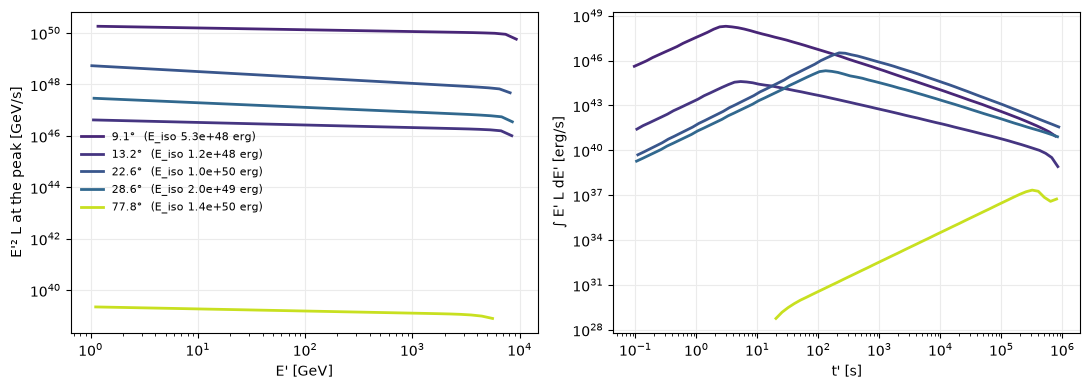

In [6]:
from matplotlib.colors import Normalize
cmap, norm = plt.cm.viridis, Normalize(0, 85)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for theta in model_set.angles_deg:
    m = model_set.models[theta]
    color = cmap(norm(theta))
    t_pk = m.peak()[0]
    axes[0].loglog(m.energy, m.at(m.energy, np.array([t_pk]))[:, 0] * m.energy ** 2, color=color, lw=2,
                   label=f"{theta:.1f}°  (E_iso {m.E_iso:.1e} erg)")
    axes[1].loglog(m.time, m.light_curve(), color=color, lw=2)
axes[0].set_xlabel("E' [GeV]"); axes[0].set_ylabel("E'² L at the peak [GeV/s]")
axes[1].set_xlabel("t' [s]"); axes[1].set_ylabel("∫ E' L dE' [erg/s]")
axes[0].legend(fontsize=8, frameon=False)
for ax in axes:
    ax.grid(True, which="major", color="0.92", lw=0.8)
fig.tight_layout()
plt.show()

## Save

One `.npz` per angle in `data/models/grb_afterglow_inaf/standardized/`, loadable with
`grb_model.GRBModelSet.load(paths.GRB_MODEL_STANDARDIZED_DIR)`. To inject it, set `model_dir_3d` to that
directory in `3_upper_limits` and draw only the tabulated angles (`THETA_MODE = "fixed"`).

In [7]:
model_set.save(paths.GRB_MODEL_STANDARDIZED_DIR)

reloaded = grb_model.GRBModelSet.load(paths.GRB_MODEL_STANDARDIZED_DIR)
assert np.allclose(reloaded.angles_deg, model_set.angles_deg)
print(f"Standardized cache written: {len(reloaded.models)} angle(s) in "
      f"{paths.GRB_MODEL_STANDARDIZED_DIR}")
for f in sorted(paths.GRB_MODEL_STANDARDIZED_DIR.glob('*.npz')):
    print(" ", f.name)


Standardized cache written: 5 angle(s) in /home/jjimenezq/projects/gw-gamma-global-uls/data/models/grb_afterglow_inaf/standardized
  theta_009.075deg.npz
  theta_013.167deg.npz
  theta_022.631deg.npz
  theta_028.554deg.npz
  theta_077.841deg.npz
